# Choosing a pulse pattern

More pulses per period deliver more neutrons, but the gain in measurement
time depends on how the spectra of the pulses are kept apart or analysed
together. This notebook compares, for N pulses of 200 µs per 50 ms period:

* one longer pulse of N × 200 µs,
* N equally spaced pulses, with and without an ideal bandwidth chopper,
* N pulses at random times and a maximum-length (pseudorandom) sequence,
* N pulses at times optimised for the edge position (strain).

All numbers are Cramér–Rao bounds of the Rietveld fit, which reaches them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import nbragg
import frame_overlap as fo

# the material, as in nbragg: 2 cm of alpha-iron
xs = nbragg.CrossSection(materials={"iron": {"mat": "Fe_sg229_Iron-alpha.ncmat"}})
model = nbragg.TransmissionModel(xs, response="jorgensen_inv", tof_length=9.0, vary_response=False)
model.params["thickness"].set(value=2.0)     # cm
model.params["α0"].set(value=3000.0)         # moderator response (rise), close to a water moderator
model.params["β0"].set(value=50.0)           # moderator response (decay)
sample = fo.Sample(model, free=["thickness", "strain"])

# the instrument: 9 m flight path, 50 ms period, 10 us bins, a thermal moderator
grid = fo.TimeGrid(flight_path=9.0, frequency=20.0, bin_width=10e-6)
beam = fo.OpenBeam.maxwellian(grid, flux=5e6, area=0.03)
hours = 8

The reference is one 200 µs pulse per period without a bandwidth
chopper. ``gain`` gives the time-reduction factor of a design against it, and
``survey`` does the same for many designs at once.

In [2]:
one = fo.Experiment(sample, beam, fo.Pattern.single(200e-6), time=hours * 3600)
print(one.precision())
fo.survey(one, {"one pulse": fo.Pattern.single(200e-6),
                "two pulses, 0 and 25 ms": fo.Pattern.times([0, 25e-3]),
                "POLDI-like sequence": fo.Pattern.poldi(grid=grid)}).round(3)

   parameter  value     sigma unit  sigma_microstrain
0  thickness    2.0  0.000761   cm                NaN
1     strain    0.0  0.000172    1         172.090732


,design,n_pulses,sigma_thickness,R_thickness,sigma_strain,R_strain
0,one pulse,1,0.001,1.000,0.0,1.000
1,"two pulses, 0 and 25 ms",2,0.001,2.000,0.0,1.999
2,POLDI-like sequence,8,0.000,4.858,0.0,2.647


A bandwidth chopper passes only part of each spectrum, so that the
spectra of N equally spaced pulses do not overlap. ``with_band_for(n)`` gives
the open beam of such a chopper: the band 0.97–5.25 Å while it fits between
the pulses, otherwise the widest band that still reaches 4.55 Å, just beyond
the (110) edge of iron.

In [3]:
rows = []
for n in [1, 2, 4, 8]:
    designs = {"one longer pulse": fo.Pattern([0.0], n * 200e-6),
               "equal, no chopper": fo.Pattern.equal(n, grid=grid),
               "random times": fo.Pattern.random(n, grid=grid, seed=n)}
    if n in (2, 4, 8):
        designs["maximum-length sequence"] = fo.Pattern.maximum_length({2: 2, 4: 3, 8: 4}[n], grid=grid)
    for name, p in designs.items():
        rows.append(dict(N=n, design=name, **one.with_pattern(p).gain(reference=one)))
    chopped = one.with_beam(beam.with_band_for(n)).with_pattern(fo.Pattern.equal(n, grid=grid))
    rows.append(dict(N=n, design="equal, bandwidth chopper", **chopped.gain(reference=one)))
    if n > 1:
        best = fo.optimise_pattern(one, n, target="strain", n_restarts=2, n_steps=400, seed=n)
        rows.append(dict(N=n, design="optimised for strain", **one.with_pattern(best).gain(reference=one)))
import pandas as pd
table = pd.DataFrame(rows)
table.pivot(index="N", columns="design", values="strain").round(2)

design,"equal, bandwidth chopper","equal, no chopper",maximum-length sequence,one longer pulse,optimised for strain,random times
N,,,,,,
1,1.00,1.00,NaN,1.00,NaN,1.00
2,2.00,2.00,1.99,1.02,2.00,1.99
4,4.00,3.33,2.57,0.92,3.91,1.82
8,7.27,1.02,2.66,0.73,4.57,2.46


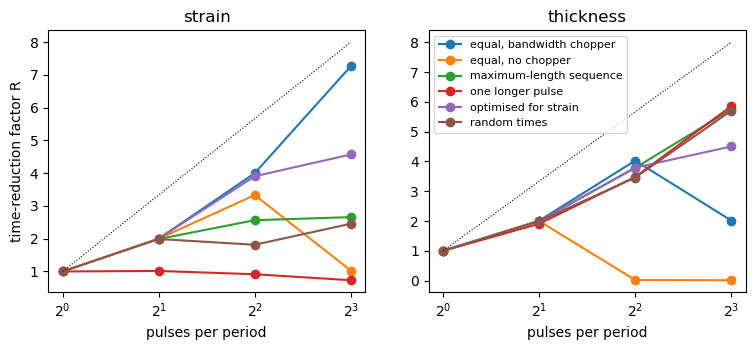

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharex=True)
for ax, par in zip(axes, ["strain", "thickness"]):
    for name, g in table.groupby("design"):
        ax.plot(g.N, g[par], "o-", label=name)
    ax.plot([1, 8], [1, 8], "k:", lw=0.8)
    ax.set_xscale("log", base=2); ax.set_xlabel("pulses per period"); ax.set_title(par)
axes[0].set_ylabel("time-reduction factor R")
axes[1].legend(fontsize=8)
plt.show()

With a bandwidth chopper the pulses do not overlap and R grows with N as
long as the band needed for the edges fits between pulses; beyond that the
narrower band keeps gaining for the strain only if the edge shape is known.
Without a chopper the spectra overlap, and optimised pulse times keep the
thermal peak of each pulse away from the edges of the others. Pseudorandom
sequences are designed for an inversion with the least noise, which the
Rietveld fit does not need. A longer pulse helps the thickness but not the
edge position.

The optimiser is a stochastic search: more restarts and steps can find
better patterns. ``optimise_pattern(..., target="thickness")`` optimises for
the thickness instead.